In [1]:
# ============================================================
# HY / HTY ovarian H3K27ac + H3K4me3 promoter peak overlap
#
# Analysis:
# 1. Read 4 ChIPseeker annotation files
# 2. Keep promoter peaks only
# 3. Within each breed:
#       H3K27ac ∩ H3K4me3
# 4. Compare HY vs HTY
#       HY-specific
#       HTY-specific
#       Shared
# 5. Save all results
#
# HY  = HY
# HTY = HTY
# ============================================================


# ============================================================
# 0. Load packages
# ============================================================

library(data.table)
library(GenomicRanges)
library(IRanges)
library(dplyr)


# ============================================================
# 1. Set input/output directory
# ============================================================

# 修改成你的实际路径
input_dir <- "."

output_dir <- "Promoter_H3K27ac_H3K4me3_overlap"

if (!dir.exists(output_dir)) {
    dir.create(output_dir, recursive = TRUE)
}


# ============================================================
# 2. Input files
# ============================================================

files <- list(

    HTY_H3K27ac =
        file.path(
            input_dir,
            "HTY_ovary_H3K27ac.ChIPseeker.annotation.tsv"
        ),

    HTY_H3K4me3 =
        file.path(
            input_dir,
            "HTY_ovary_H3K4me3.ChIPseeker.annotation.tsv"
        ),

    HY_H3K27ac =
        file.path(
            input_dir,
            "HY_ovary_H3K27ac.ChIPseeker.annotation.tsv"
        ),

    HY_H3K4me3 =
        file.path(
            input_dir,
            "HY_ovary_H3K4me3.ChIPseeker.annotation.tsv"
        )
)


# ============================================================
# 3. Check files
# ============================================================

cat("\nChecking input files...\n")

for (f in files) {

    if (!file.exists(f)) {
        stop(
            paste0(
                "\nFile not found:\n",
                f
            )
        )
    }

    cat("Found: ", f, "\n")
}


# ============================================================
# 4. Read files
# ============================================================

cat("\nReading annotation files...\n")

dat <- lapply(
    files,
    function(f) {
        fread(
            f,
            sep = "\t",
            header = TRUE,
            data.table = FALSE
        )
    }
)

names(dat) <- names(files)


# ============================================================
# 5. Check columns
# ============================================================

cat("\nColumn names:\n")

for (i in names(dat)) {

    cat("\n----------------------------------------\n")
    cat(i, "\n")
    print(colnames(dat[[i]]))
}


# ============================================================
# 6. Check required columns
# ============================================================

required_columns <- c(
    "seqnames",
    "start",
    "end",
    "annotation"
)

for (i in names(dat)) {

    missing_columns <- setdiff(
        required_columns,
        colnames(dat[[i]])
    )

    if (length(missing_columns) > 0) {

        stop(
            paste0(
                "\nMissing columns in ",
                i,
                ": ",
                paste(missing_columns, collapse = ", ")
            )
        )
    }
}


# ============================================================
# 7. Identify gene column
#
# ChIPseeker usually contains:
# SYMBOL
# geneId
#
# We keep both if available.
# ============================================================

gene_symbol_col <- "SYMBOL"
gene_id_col <- "geneId"

for (i in names(dat)) {

    if (!gene_symbol_col %in% colnames(dat[[i]])) {

        warning(
            paste0(
                "\n",
                i,
                " does not contain SYMBOL column."
            )
        )
    }

    if (!gene_id_col %in% colnames(dat[[i]])) {

        warning(
            paste0(
                "\n",
                i,
                " does not contain geneId column."
            )
        )
    }
}


# ============================================================
# 8. Keep promoter peaks
#
# Important:
#
# ChIPseeker annotation can be:
#
# Promoter (<=1kb)
# Promoter (1-2kb)
# Promoter (2-3kb)
#
# Therefore use grepl("Promoter")
# rather than annotation == "Promoter"
# ============================================================

dat_promoter <- lapply(
    dat,
    function(df) {

        df %>%
            filter(
                !is.na(annotation),
                grepl(
                    "Promoter",
                    annotation,
                    ignore.case = TRUE
                )
            )
    }
)


# ============================================================
# 9. Print number of promoter peaks
# ============================================================

cat("\n========================================\n")
cat("Promoter peak numbers\n")
cat("========================================\n")

for (i in names(dat_promoter)) {

    cat(
        sprintf(
            "%-20s %d\n",
            i,
            nrow(dat_promoter[[i]])
        )
    )
}


# ============================================================
# 10. Function:
#     convert annotation dataframe -> GRanges
# ============================================================

make_gr <- function(df) {

    # --------------------------------------------------------
    # Gene SYMBOL
    # --------------------------------------------------------

    if ("SYMBOL" %in% colnames(df)) {

        symbol <- as.character(df$SYMBOL)

    } else {

        symbol <- rep(
            NA_character_,
            nrow(df)
        )
    }


    # --------------------------------------------------------
    # geneId
    # --------------------------------------------------------

    if ("geneId" %in% colnames(df)) {

        gene_id <- as.character(df$geneId)

    } else {

        gene_id <- rep(
            NA_character_,
            nrow(df)
        )
    }


    # --------------------------------------------------------
    # Peak ID
    #
    # If your file has peak_id, preserve it.
    # Otherwise create one from coordinates.
    # --------------------------------------------------------

    if ("peak_id" %in% colnames(df)) {

        peak_id <- as.character(df$peak_id)

    } else {

        peak_id <- paste0(
            as.character(df$seqnames),
            ":",
            df$start,
            "-",
            df$end
        )
    }


    # --------------------------------------------------------
    # GRanges
    # --------------------------------------------------------

    gr <- GRanges(
        seqnames = as.character(df$seqnames),

        ranges = IRanges(
            start = as.integer(df$start),
            end = as.integer(df$end)
        )
    )


    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    mcols(gr)$peak_id <- peak_id
    mcols(gr)$annotation <- as.character(df$annotation)
    mcols(gr)$geneId <- gene_id
    mcols(gr)$SYMBOL <- symbol

    return(gr)
}


# ============================================================
# 11. Convert all promoter peaks to GRanges
# ============================================================

gr <- lapply(
    dat_promoter,
    make_gr
)


# ============================================================
# 12. Function:
#     overlap two omics within one breed
#
#     H3K27ac ∩ H3K4me3
#
# type = "any"
# means any genomic overlap is enough.
# ============================================================

get_omics_overlap <- function(
    gr_k27,
    gr_k4,
    breed
) {

    # --------------------------------------------------------
    # Find genomic overlaps
    # --------------------------------------------------------

    hits <- findOverlaps(
        gr_k27,
        gr_k4,
        type = "any",
        ignore.strand = TRUE
    )


    cat(
        "\n",
        breed,
        "H3K27ac-H3K4me3 overlap pairs: ",
        length(hits),
        "\n",
        sep = ""
    )


    # --------------------------------------------------------
    # No overlap
    # --------------------------------------------------------

    if (length(hits) == 0) {

        return(
            list(
                hits = hits,
                overlap_gr = GRanges(),
                table = data.frame()
            )
        )
    }


    # --------------------------------------------------------
    # Matched peaks
    # --------------------------------------------------------

    k27 <- gr_k27[
        queryHits(hits)
    ]

    k4 <- gr_k4[
        subjectHits(hits)
    ]


    # --------------------------------------------------------
    # Actual intersection region
    #
    # This creates the genomic region shared by the two peaks.
    # --------------------------------------------------------

    intersection_gr <- pintersect(
        k27,
        k4
    )


    # --------------------------------------------------------
    # Create unique overlap ID
    # --------------------------------------------------------

    overlap_id <- paste0(
        breed,
        "_H3K27ac_H3K4me3_",
        seq_along(intersection_gr)
    )


    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    mcols(intersection_gr)$overlap_id <-
        overlap_id

    mcols(intersection_gr)$K27ac_peak_id <-
        mcols(k27)$peak_id

    mcols(intersection_gr)$K4me3_peak_id <-
        mcols(k4)$peak_id

    mcols(intersection_gr)$K27ac_annotation <-
        mcols(k27)$annotation

    mcols(intersection_gr)$K4me3_annotation <-
        mcols(k4)$annotation

    mcols(intersection_gr)$K27ac_SYMBOL <-
        mcols(k27)$SYMBOL

    mcols(intersection_gr)$K4me3_SYMBOL <-
        mcols(k4)$SYMBOL

    mcols(intersection_gr)$K27ac_geneId <-
        mcols(k27)$geneId

    mcols(intersection_gr)$K4me3_geneId <-
        mcols(k4)$geneId


    # --------------------------------------------------------
    # Create result table
    # --------------------------------------------------------

    result <- data.frame(

        overlap_id =
            overlap_id,

        chr =
            as.character(
                seqnames(intersection_gr)
            ),

        start =
            start(intersection_gr),

        end =
            end(intersection_gr),

        width =
            width(intersection_gr),

        K27ac_peak_id =
            mcols(k27)$peak_id,

        K27ac_start =
            start(k27),

        K27ac_end =
            end(k27),

        K4me3_peak_id =
            mcols(k4)$peak_id,

        K4me3_start =
            start(k4),

        K4me3_end =
            end(k4),

        K27ac_SYMBOL =
            mcols(k27)$SYMBOL,

        K4me3_SYMBOL =
            mcols(k4)$SYMBOL,

        K27ac_geneId =
            mcols(k27)$geneId,

        K4me3_geneId =
            mcols(k4)$geneId,

        K27ac_annotation =
            mcols(k27)$annotation,

        K4me3_annotation =
            mcols(k4)$annotation,

        stringsAsFactors = FALSE
    )


    return(
        list(
            hits = hits,
            overlap_gr = intersection_gr,
            table = result
        )
    )
}


# ============================================================
# 13. HY internal overlap
# ============================================================

cat("\n========================================\n")
cat("HY internal overlap\n")
cat("========================================\n")

HY_result <- get_omics_overlap(
    gr_k27 = gr$HY_H3K27ac,
    gr_k4  = gr$HY_H3K4me3,
    breed  = "HY"
)


# ============================================================
# 14. HTY internal overlap
# ============================================================

cat("\n========================================\n")
cat("HTY internal overlap\n")
cat("========================================\n")

HTY_result <- get_omics_overlap(
    gr_k27 = gr$HTY_H3K27ac,
    gr_k4  = gr$HTY_H3K4me3,
    breed  = "HTY"
)


# ============================================================
# 15. Save internal overlap results
# ============================================================

fwrite(
    HY_result$table,
    file.path(
        output_dir,
        "HY_H3K27ac_H3K4me3_Promoter_overlap.tsv"
    ),
    sep = "\t"
)

fwrite(
    HTY_result$table,
    file.path(
        output_dir,
        "HTY_H3K27ac_H3K4me3_Promoter_overlap.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 16. Save BED files for internal overlap
# ============================================================

HY_bed <- HY_result$table %>%
    select(
        chr,
        start,
        end,
        overlap_id
    )

HTY_bed <- HTY_result$table %>%
    select(
        chr,
        start,
        end,
        overlap_id
    )


fwrite(
    HY_bed,
    file.path(
        output_dir,
        "HY_H3K27ac_H3K4me3_Promoter_overlap.bed"
    ),
    sep = "\t",
    col.names = FALSE
)

fwrite(
    HTY_bed,
    file.path(
        output_dir,
        "HTY_H3K27ac_H3K4me3_Promoter_overlap.bed"
    ),
    sep = "\t",
    col.names = FALSE
)


# ============================================================
# 17. Convert internal overlap results to GRanges
# ============================================================

HY_overlap_gr <- HY_result$overlap_gr
HTY_overlap_gr <- HTY_result$overlap_gr


# ============================================================
# 18. Compare HY vs HTY
#
# IMPORTANT:
#
# Here we compare:
#
# HY:
#     H3K27ac ∩ H3K4me3 promoter regions
#
# against
#
# HTY:
#     H3K27ac ∩ H3K4me3 promoter regions
#
# Any genomic overlap = shared
# ============================================================

breed_hits <- findOverlaps(
    HY_overlap_gr,
    HTY_overlap_gr,
    type = "any",
    ignore.strand = TRUE
)


cat("\n========================================\n")
cat("HY vs HTY comparison\n")
cat("========================================\n")

cat(
    "HY double-omics regions: ",
    length(HY_overlap_gr),
    "\n"
)

cat(
    "HTY double-omics regions: ",
    length(HTY_overlap_gr),
    "\n"
)

cat(
    "HY-HTY overlap pairs: ",
    length(breed_hits),
    "\n"
)


# ============================================================
# 19. Identify shared regions
# ============================================================

HY_shared_idx <- unique(
    queryHits(breed_hits)
)

HTY_shared_idx <- unique(
    subjectHits(breed_hits)
)


# ============================================================
# 20. Identify breed-specific regions
# ============================================================

HY_specific_idx <- setdiff(
    seq_along(HY_overlap_gr),
    HY_shared_idx
)

HTY_specific_idx <- setdiff(
    seq_along(HTY_overlap_gr),
    HTY_shared_idx
)


# ============================================================
# 21. Extract GRanges
# ============================================================

HY_specific_gr <- HY_overlap_gr[
    HY_specific_idx
]

HTY_specific_gr <- HTY_overlap_gr[
    HTY_specific_idx
]

HY_shared_gr <- HY_overlap_gr[
    HY_shared_idx
]

HTY_shared_gr <- HTY_overlap_gr[
    HTY_shared_idx
]


# ============================================================
# 22. Function to convert GRanges to table
# ============================================================

gr_to_table <- function(gr) {

    if (length(gr) == 0) {

        return(
            data.frame()
        )
    }


    result <- data.frame(

        chr =
            as.character(
                seqnames(gr)
            ),

        start =
            start(gr),

        end =
            end(gr),

        width =
            width(gr),

        overlap_id =
            mcols(gr)$overlap_id,

        K27ac_peak_id =
            mcols(gr)$K27ac_peak_id,

        K4me3_peak_id =
            mcols(gr)$K4me3_peak_id,

        K27ac_SYMBOL =
            mcols(gr)$K27ac_SYMBOL,

        K4me3_SYMBOL =
            mcols(gr)$K4me3_SYMBOL,

        K27ac_geneId =
            mcols(gr)$K27ac_geneId,

        K4me3_geneId =
            mcols(gr)$K4me3_geneId,

        K27ac_annotation =
            mcols(gr)$K27ac_annotation,

        K4me3_annotation =
            mcols(gr)$K4me3_annotation,

        stringsAsFactors = FALSE
    )


    return(result)
}


# ============================================================
# 23. Create result tables
# ============================================================

HY_specific <- gr_to_table(
    HY_specific_gr
)

HTY_specific <- gr_to_table(
    HTY_specific_gr
)

HY_shared <- gr_to_table(
    HY_shared_gr
)

HTY_shared <- gr_to_table(
    HTY_shared_gr
)


# ============================================================
# 24. Save HY-specific
# ============================================================

fwrite(
    HY_specific,
    file.path(
        output_dir,
        "HY_specific_H3K27ac_H3K4me3_Promoter_peak.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 25. Save HTY-specific
# ============================================================

fwrite(
    HTY_specific,
    file.path(
        output_dir,
        "HTY_specific_H3K27ac_H3K4me3_Promoter_peak.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 26. Save shared HY side
# ============================================================

fwrite(
    HY_shared,
    file.path(
        output_dir,
        "HY_HTY_shared_H3K27ac_H3K4me3_Promoter_HY.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 27. Save shared HTY side
# ============================================================

fwrite(
    HTY_shared,
    file.path(
        output_dir,
        "HY_HTY_shared_H3K27ac_H3K4me3_Promoter_HTY.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 28. Save BED files
# ============================================================

if (nrow(HY_specific) > 0) {

    fwrite(
        HY_specific %>%
            select(
                chr,
                start,
                end,
                overlap_id
            ),
        file.path(
            output_dir,
            "HY_specific_H3K27ac_H3K4me3_Promoter_peak.bed"
        ),
        sep = "\t",
        col.names = FALSE
    )
}


if (nrow(HTY_specific) > 0) {

    fwrite(
        HTY_specific %>%
            select(
                chr,
                start,
                end,
                overlap_id
            ),
        file.path(
            output_dir,
            "HTY_specific_H3K27ac_H3K4me3_Promoter_peak.bed"
        ),
        sep = "\t",
        col.names = FALSE
    )
}


# ============================================================
# 29. Extract genes from breed-specific peaks
#
# Combine genes annotated by H3K27ac and H3K4me3.
# ============================================================

extract_genes <- function(df) {

    if (nrow(df) == 0) {
        return(character(0))
    }


    genes <- c(
        df$K27ac_SYMBOL,
        df$K4me3_SYMBOL
    )


    genes <- genes[
        !is.na(genes) &
        genes != "" &
        genes != "."
    ]


    genes <- unique(
        genes
    )


    return(
        sort(genes)
    )
}


HY_specific_genes <- extract_genes(
    HY_specific
)

HTY_specific_genes <- extract_genes(
    HTY_specific
)


# ============================================================
# 30. Save gene lists
# ============================================================

write.table(
    HY_specific_genes,
    file.path(
        output_dir,
        "HY_specific_Promoter_genes.txt"
    ),
    quote = FALSE,
    row.names = FALSE,
    col.names = FALSE
)


write.table(
    HTY_specific_genes,
    file.path(
        output_dir,
        "HTY_specific_Promoter_genes.txt"
    ),
    quote = FALSE,
    row.names = FALSE,
    col.names = FALSE
)


# ============================================================
# 31. Summary
# ============================================================

summary_df <- data.frame(

    category = c(
        "HY promoter H3K27ac",
        "HY promoter H3K4me3",
        "HY H3K27ac-H3K4me3 overlap",
        "HY-specific double-omics promoter",
        "HY shared",

        "HTY promoter H3K27ac",
        "HTY promoter H3K4me3",
        "HTY H3K27ac-H3K4me3 overlap",
        "HTY-specific double-omics promoter",
        "HTY shared"
    ),

    number = c(

        length(gr$HY_H3K27ac),

        length(gr$HY_H3K4me3),

        length(HY_overlap_gr),

        length(HY_specific_gr),

        length(HY_shared_gr),

        length(gr$HTY_H3K27ac),

        length(gr$HTY_H3K4me3),

        length(HTY_overlap_gr),

        length(HTY_specific_gr),

        length(HTY_shared_gr)
    )
)


print(summary_df)


# ============================================================
# 32. Save summary
# ============================================================

fwrite(
    summary_df,
    file.path(
        output_dir,
        "peak_overlap_summary.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 33. Print final result
# ============================================================

cat("\n")
cat("========================================\n")
cat("Analysis finished!\n")
cat("========================================\n")

cat(
    "HY-specific peaks: ",
    length(HY_specific_gr),
    "\n"
)

cat(
    "HTY-specific peaks: ",
    length(HTY_specific_gr),
    "\n"
)

cat(
    "HY shared peaks: ",
    length(HY_shared_gr),
    "\n"
)

cat(
    "HTY shared peaks: ",
    length(HTY_shared_gr),
    "\n"
)

cat(
    "HY-specific genes: ",
    length(HY_specific_genes),
    "\n"
)

cat(
    "HTY-specific genes: ",
    length(HTY_specific_genes),
    "\n"
)

cat(
    "\nResults saved to:\n",
    output_dir,
    "\n"
)

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, saveRDS, setdiff,
    table, tapply, union, unique, unsplit, which.max, which.min


Loading required package: S4Vectors


Attaching package: ‘S4Vectors’


The following objects are masked from ‘package:data.table’:

    first, second


The following object is masked from ‘package:utils’:

    findMatches


The following objects are masked from ‘package:base’:

    expand.grid, I, unname


Loading required package: IRanges




Checking input files...
Found:  ./HTY_ovary_H3K27ac.ChIPseeker.annotation.tsv 
Found:  ./HTY_ovary_H3K4me3.ChIPseeker.annotation.tsv 
Found:  ./HY_ovary_H3K27ac.ChIPseeker.annotation.tsv 
Found:  ./HY_ovary_H3K4me3.ChIPseeker.annotation.tsv 

Reading annotation files...

Column names:

----------------------------------------
HTY_H3K27ac 
 [1] "seqnames"      "start"         "end"           "width"        
 [5] "strand"        "annotation"    "geneChr"       "geneStart"    
 [9] "geneEnd"       "geneLength"    "geneStrand"    "geneId"       
[13] "transcriptId"  "distanceToTSS"

----------------------------------------
HTY_H3K4me3 
 [1] "seqnames"      "start"         "end"           "width"        
 [5] "strand"        "annotation"    "geneChr"       "geneStart"    
 [9] "geneEnd"       "geneLength"    "geneStrand"    "geneId"       
[13] "transcriptId"  "distanceToTSS"

----------------------------------------
HY_H3K27ac 
 [1] "seqnames"      "start"         "end"           "width" 

Warning message:
“
HTY_H3K27ac does not contain SYMBOL column.”
Warning message:
“
HTY_H3K4me3 does not contain SYMBOL column.”
Warning message:
“
HY_H3K27ac does not contain SYMBOL column.”
Warning message:
“
HY_H3K4me3 does not contain SYMBOL column.”



Promoter peak numbers
HTY_H3K27ac          2102
HTY_H3K4me3          4973
HY_H3K27ac           2238
HY_H3K4me3           8024

HY internal overlap


Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': NW_014639376.1, NW_014639409.1, NW_014639507.1, NW_014639524.1, NW_014639767.1, NW_014639813.1, NW_014639904.1, NW_014640064.1, NW_014640113.1, NW_014640175.1, NW_014640195.1, NW_014640256.1, NW_014640279.1, NW_014640286.1, NW_014640317.1, NW_014640328.1, NW_014640480.1, NW_014640595.1, NW_014640655.1, NW_014640681.1, NW_014640682.1, NW_014640701.1, NW_014640778.1, NW_014640867.1, NW_014641052.1, NW_014641096.1, NW_014641195.1, NW_014641396.1, NW_014641629.1, NW_014641833.1, NW_014641889.1, NW_014641904.1, NW_014642026.1, NW_014642185.1, NW_014642360.1, NW_014642381.1, NW_014642670.1, NW_014642753.1, NW_014642797.1, NW_014642804.1, NW_014642811.1, NW_014642814.1, NW_014642874.1, NW_014643774.1, NW_014644242.1
  - in 'y': NW_014639041.1, NW_014639084.1, NW_014639135.1, NW_014639164.1, NW_014639183.1, NW_014639203.1, NW_014639221.1, NW_014639232.1, NW_014


HYH3K27ac-H3K4me3 overlap pairs: 1001


... (2 outputs left out)

Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': NW_014639041.1, NW_014639092.1, NW_014639203.1, NW_014639235.1, NW_014639351.1, NW_014639369.1, NW_014639376.1, NW_014639393.1, NW_014639410.1, NW_014639426.1, NW_014639465.1, NW_014639474.1, NW_014639507.1, NW_014639547.1, NW_014639556.1, NW_014639703.1, NW_014639765.1, NW_014639877.1, NW_014639900.1, NW_014639966.1, NW_014639989.1, NW_014639991.1, NW_014640076.1, NW_014640213.1, NW_014640367.1, NW_014640412.1, NW_014640450.1, NW_014640484.1, NW_014640558.1, NW_014640581.1, NW_014640667.1, NW_014640705.1, NW_014640777.1, NW_014640812.1, NW_014640869.1, NW_014641072.1, NW_014641096.1, NW_014641162.1, NW_014641164.1, NW_014641177.1, NW_014641244.1, NW_014641316.1, NW_014641321.1, NW_014641397.1, NW_014641463.1, NW_014641515.1, NW_014641654.1, NW_014641672.1, NW_014641696.1, NW_014641724.1, NW_014641731.1, NW_014641741.1, NW_014641839.1, NW_014641846.1, N


HTYH3K27ac-H3K4me3 overlap pairs: 748


Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': NW_014639041.1, NW_014639092.1, NW_014639203.1, NW_014639235.1, NW_014639351.1, NW_014639369.1, NW_014639376.1, NW_014639393.1, NW_014639410.1, NW_014639426.1, NW_014639465.1, NW_014639474.1, NW_014639507.1, NW_014639547.1, NW_014639556.1, NW_014639703.1, NW_014639765.1, NW_014639877.1, NW_014639900.1, NW_014639966.1, NW_014639989.1, NW_014639991.1, NW_014640076.1, NW_014640213.1, NW_014640367.1, NW_014640412.1, NW_014640450.1, NW_014640484.1, NW_014640558.1, NW_014640581.1, NW_014640667.1, NW_014640705.1, NW_014640777.1, NW_014640812.1, NW_014640869.1, NW_014641072.1, NW_014641096.1, NW_014641162.1, NW_014641164.1, NW_014641177.1, NW_014641244.1, NW_014641316.1, NW_014641321.1, NW_014641397.1, NW_014641463.1, NW_014641515.1, NW_014641654.1, NW_014641672.1, NW_014641696.1, NW_014641724.1, NW_014641731.1, NW_014641741.1, NW_014641839.1, NW_014641846.1, N


HY vs HTY comparison
HY double-omics regions:  1001 
HTY double-omics regions:  748 
HY-HTY overlap pairs:  362 
                             category number
1                 HY promoter H3K27ac   2238
2                 HY promoter H3K4me3   8024
3          HY H3K27ac-H3K4me3 overlap   1001
4   HY-specific double-omics promoter    639
5                           HY shared    362
6                HTY promoter H3K27ac   2102
7                HTY promoter H3K4me3   4973
8         HTY H3K27ac-H3K4me3 overlap    748
9  HTY-specific double-omics promoter    386
10                         HTY shared    362

Analysis finished!
HY-specific peaks:  639 
HTY-specific peaks:  386 
HY shared peaks:  362 
HTY shared peaks:  362 
HY-specific genes:  0 
HTY-specific genes:  0 

Results saved to:
 Promoter_H3K27ac_H3K4me3_overlap 


In [13]:
# ============================================================
# HY vs HTY H3K27ac breed-specific peaks
#
# Input:
#   HY_H3K27ac_specific_nearby_genes.tsv
#   HTY_H3K27ac_specific_nearby_genes.tsv
#
# Columns:
# peak_id
# peak_chr
# peak_start
# peak_end
# gene_id
# gene_symbol
# strand
# TSS
# distance_to_TSS
# distance_to_TSS_abs
# relative_position
#
# Output:
#   HY-specific peaks
#   HTY-specific peaks
#   shared peaks
#   nearby genes
#   BED files
# ============================================================


library(data.table)
library(GenomicRanges)
library(IRanges)
library(dplyr)


# ============================================================
# 1. Input / output
# ============================================================

HY_file <- "HY_H3K27ac_specific_nearby_genes.tsv"

HTY_file <- "HTY_H3K27ac_specific_nearby_genes.tsv"

outdir <- "HY_HTY_H3K27ac_differential_peak"

if (!dir.exists(outdir)) {
    dir.create(outdir, recursive = TRUE)
}


# ============================================================
# 2. Read files
# ============================================================

HY <- fread(
    HY_file,
    sep = "\t",
    header = TRUE,
    data.table = FALSE
)

HTY <- fread(
    HTY_file,
    sep = "\t",
    header = TRUE,
    data.table = FALSE
)


# ============================================================
# 3. Check columns
# ============================================================

required_cols <- c(
    "peak_id",
    "peak_chr",
    "peak_start",
    "peak_end",
    "gene_id",
    "gene_symbol",
    "strand",
    "TSS",
    "distance_to_TSS",
    "distance_to_TSS_abs",
    "relative_position"
)

for (x in required_cols) {

    if (!x %in% colnames(HY)) {

        stop(
            paste0(
                "HY missing column: ",
                x
            )
        )
    }

    if (!x %in% colnames(HTY)) {

        stop(
            paste0(
                "HTY missing column: ",
                x
            )
        )
    }
}


cat("\nInput files loaded successfully.\n")

cat(
    "HY rows: ",
    nrow(HY),
    "\n"
)

cat(
    "HTY rows: ",
    nrow(HTY),
    "\n"
)


# ============================================================
# 4. Check duplicated peak_id
#
# One peak may have multiple nearby genes.
# Therefore the original table may contain:
#
# peak1 geneA
# peak1 geneB
# peak2 geneC
#
# For genomic peak comparison, each peak should appear once.
# ============================================================

cat("\n========================================\n")
cat("Duplicated peak statistics\n")
cat("========================================\n")

cat(
    "HY unique peaks: ",
    length(unique(HY$peak_id)),
    "\n"
)

cat(
    "HTY unique peaks: ",
    length(unique(HTY$peak_id)),
    "\n"
)


# ============================================================
# 5. Create unique peak table
#
# Keep the first row for genomic comparison.
# Nearby genes will be merged separately later.
# ============================================================

HY_peak <- HY %>%
    distinct(
        peak_id,
        .keep_all = TRUE
    )

HTY_peak <- HTY %>%
    distinct(
        peak_id,
        .keep_all = TRUE
    )


# ============================================================
# 6. Create GRanges
# ============================================================

HY_gr <- GRanges(

    seqnames = HY_peak$peak_chr,

    ranges = IRanges(
        start = as.integer(HY_peak$peak_start),
        end   = as.integer(HY_peak$peak_end)
    )
)


HTY_gr <- GRanges(

    seqnames = HTY_peak$peak_chr,

    ranges = IRanges(
        start = as.integer(HTY_peak$peak_start),
        end   = as.integer(HTY_peak$peak_end)
    )
)


# ============================================================
# 7. Add peak_id to GRanges
# ============================================================

mcols(HY_gr)$peak_id <- HY_peak$peak_id

mcols(HTY_gr)$peak_id <- HTY_peak$peak_id


# ============================================================
# 8. Check chromosomes
# ============================================================

cat("\n========================================\n")
cat("Chromosome information\n")
cat("========================================\n")

cat("\nHY chromosomes:\n")
print(sort(unique(as.character(seqnames(HY_gr)))))

cat("\nHTY chromosomes:\n")
print(sort(unique(as.character(seqnames(HTY_gr)))))


# ============================================================
# 9. Find genomic overlap
#
# type = "any":
# Any overlap between two peaks is considered shared.
# ============================================================

hits <- findOverlaps(
    HY_gr,
    HTY_gr,
    type = "any",
    ignore.strand = TRUE
)


cat("\n========================================\n")
cat("HY vs HTY genomic overlap\n")
cat("========================================\n")

cat(
    "Overlap pairs: ",
    length(hits),
    "\n"
)


# ============================================================
# 10. Identify shared peak IDs
# ============================================================

HY_shared_idx <- unique(
    queryHits(hits)
)

HTY_shared_idx <- unique(
    subjectHits(hits)
)


HY_shared_ids <- HY_peak$peak_id[
    HY_shared_idx
]

HTY_shared_ids <- HTY_peak$peak_id[
    HTY_shared_idx
]


# ============================================================
# 11. Identify breed-specific peaks
# ============================================================

HY_specific_idx <- setdiff(
    seq_len(nrow(HY_peak)),
    HY_shared_idx
)

HTY_specific_idx <- setdiff(
    seq_len(nrow(HTY_peak)),
    HTY_shared_idx
)


# ============================================================
# 12. Extract specific peaks
# ============================================================

HY_specific_peak <- HY_peak[
    HY_specific_idx,
    ,
    drop = FALSE
]

HTY_specific_peak <- HTY_peak[
    HTY_specific_idx,
    ,
    drop = FALSE
]


# ============================================================
# 13. Extract shared peaks
# ============================================================

HY_shared_peak <- HY_peak[
    HY_shared_idx,
    ,
    drop = FALSE
]

HTY_shared_peak <- HTY_peak[
    HTY_shared_idx,
    ,
    drop = FALSE
]


# ============================================================
# 14. Function:
#     restore all nearby genes
#
# Because one peak can have multiple nearby genes,
# merge all gene annotations belonging to the peak.
# ============================================================

merge_peak_genes <- function(
    original_df,
    peak_df
) {

    gene_info <- original_df %>%

        filter(
            peak_id %in% peak_df$peak_id
        ) %>%

        group_by(peak_id) %>%

        summarise(

            gene_id = paste(
                unique(
                    gene_id[
                        !is.na(gene_id) &
                        gene_id != "" &
                        gene_id != "."
                    ]
                ),
                collapse = ";"
            ),

            gene_symbol = paste(
                unique(
                    gene_symbol[
                        !is.na(gene_symbol) &
                        gene_symbol != "" &
                        gene_symbol != "."
                    ]
                ),
                collapse = ";"
            ),

            .groups = "drop"
        )


    result <- peak_df %>%

        left_join(
            gene_info,
            by = "peak_id",
            suffix = c("", "_merged")
        )


    return(result)
}


# ============================================================
# 15. Add all nearby genes
# ============================================================

HY_specific_peak <- merge_peak_genes(
    HY,
    HY_specific_peak
)

HTY_specific_peak <- merge_peak_genes(
    HTY,
    HTY_specific_peak
)

HY_shared_peak <- merge_peak_genes(
    HY,
    HY_shared_peak
)

HTY_shared_peak <- merge_peak_genes(
    HTY,
    HTY_shared_peak
)


# ============================================================
# 16. Save HY-specific
# ============================================================

fwrite(
    HY_specific_peak,
    file.path(
        outdir,
        "HY_H3K27ac_breed_specific_peak.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 17. Save HTY-specific
# ============================================================

fwrite(
    HTY_specific_peak,
    file.path(
        outdir,
        "HTY_H3K27ac_breed_specific_peak.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 18. Save shared peaks
# ============================================================

fwrite(
    HY_shared_peak,
    file.path(
        outdir,
        "HY_H3K27ac_shared_peak.tsv"
    ),
    sep = "\t"
)

fwrite(
    HTY_shared_peak,
    file.path(
        outdir,
        "HTY_H3K27ac_shared_peak.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 19. Create BED files
# ============================================================

HY_specific_bed <- HY_specific_peak %>%

    select(
        peak_chr,
        peak_start,
        peak_end,
        peak_id
    )


HTY_specific_bed <- HTY_specific_peak %>%

    select(
        peak_chr,
        peak_start,
        peak_end,
        peak_id
    )


HY_shared_bed <- HY_shared_peak %>%

    select(
        peak_chr,
        peak_start,
        peak_end,
        peak_id
    )


HTY_shared_bed <- HTY_shared_peak %>%

    select(
        peak_chr,
        peak_start,
        peak_end,
        peak_id
    )


# ============================================================
# 20. Save BED
# ============================================================

fwrite(
    HY_specific_bed,
    file.path(
        outdir,
        "HY_H3K27ac_breed_specific_peak.bed"
    ),
    sep = "\t",
    col.names = FALSE
)


fwrite(
    HTY_specific_bed,
    file.path(
        outdir,
        "HTY_H3K27ac_breed_specific_peak.bed"
    ),
    sep = "\t",
    col.names = FALSE
)


fwrite(
    HY_shared_bed,
    file.path(
        outdir,
        "HY_H3K27ac_shared_peak.bed"
    ),
    sep = "\t",
    col.names = FALSE
)


fwrite(
    HTY_shared_bed,
    file.path(
        outdir,
        "HTY_H3K27ac_shared_peak.bed"
    ),
    sep = "\t",
    col.names = FALSE
)


# ============================================================
# 21. Create gene lists
# ============================================================

HY_genes <- HY_specific_peak %>%

    select(
        peak_id,
        gene_symbol
    ) %>%

    filter(
        !is.na(gene_symbol),
        gene_symbol != "",
        gene_symbol != "."
    )


HTY_genes <- HTY_specific_peak %>%

    select(
        peak_id,
        gene_symbol
    ) %>%

    filter(
        !is.na(gene_symbol),
        gene_symbol != "",
        gene_symbol != "."
    )


# ============================================================
# 22. Save gene lists
# ============================================================

fwrite(
    HY_genes,
    file.path(
        outdir,
        "HY_H3K27ac_specific_nearby_genes.tsv"
    ),
    sep = "\t"
)


fwrite(
    HTY_genes,
    file.path(
        outdir,
        "HTY_H3K27ac_specific_nearby_genes.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 23. Summary
# ============================================================

summary_df <- data.frame(

    category = c(
        "HY input rows",
        "HY unique peaks",
        "HTY input rows",
        "HTY unique peaks",

        "HY-specific peaks",
        "HTY-specific peaks",

        "HY shared peaks",
        "HTY shared peaks",

        "HY-specific genes",
        "HTY-specific genes"
    ),

    number = c(

        nrow(HY),

        nrow(HY_peak),

        nrow(HTY),

        nrow(HTY_peak),

        nrow(HY_specific_peak),

        nrow(HTY_specific_peak),

        nrow(HY_shared_peak),

        nrow(HTY_shared_peak),

        length(
            unique(
                unlist(
                    strsplit(
                        HY_specific_peak$gene_symbol,
                        ";"
                    )
                )
            )
        ),

        length(
            unique(
                unlist(
                    strsplit(
                        HTY_specific_peak$gene_symbol,
                        ";"
                    )
                )
            )
        )
    )
)


# ============================================================
# 24. Print summary
# ============================================================

cat("\n")
cat("========================================\n")
cat("FINAL RESULT\n")
cat("========================================\n")

print(summary_df)


# ============================================================
# 25. Save summary
# ============================================================

fwrite(
    summary_df,
    file.path(
        outdir,
        "H3K27ac_differential_peak_summary.tsv"
    ),
    sep = "\t"
)


# ============================================================
# 26. Finish
# ============================================================

cat("\n========================================\n")
cat("Analysis finished!\n")
cat("========================================\n")

cat(
    "\nHY-specific peaks: ",
    nrow(HY_specific_peak),
    "\n"
)

cat(
    "HTY-specific peaks: ",
    nrow(HTY_specific_peak),
    "\n"
)

cat(
    "Shared peaks: ",
    length(
        unique(
            c(
                HY_shared_ids,
                HTY_shared_ids
            )
        )
    ),
    "\n"
)

cat(
    "\nOutput directory:\n",
    outdir,
    "\n"
)


Input files loaded successfully.
HY rows:  36123 
HTY rows:  23996 

Duplicated peak statistics
HY unique peaks:  7846 
HTY unique peaks:  9422 

Chromosome information

HY chromosomes:
 [1] "NC_001941.1"    "NC_019458.2"    "NC_019459.2"    "NC_019460.2"   
 [5] "NC_019461.2"    "NC_019462.2"    "NC_019463.2"    "NC_019464.2"   
 [9] "NC_019465.2"    "NC_019466.2"    "NC_019467.2"    "NC_019468.2"   
[13] "NC_019469.2"    "NC_019470.2"    "NC_019471.2"    "NC_019472.2"   
[17] "NC_019473.2"    "NC_019474.2"    "NC_019475.2"    "NC_019476.2"   
[21] "NC_019477.2"    "NC_019478.2"    "NC_019479.2"    "NC_019480.2"   
[25] "NC_019481.2"    "NC_019482.2"    "NC_019483.2"    "NC_019484.2"   
[29] "NW_014639275.1" "NW_014640059.1" "NW_014640270.1" "NW_014640480.1"
[33] "NW_014640580.1" "NW_014640682.1" "NW_014640775.1" "NW_014640978.1"
[37] "NW_014641052.1" "NW_014641360.1" "NW_014641638.1" "NW_014641890.1"
[41] "NW_014641901.1" "NW_014642199.1" "NW_014642381.1" "NW_014642753.1"
[45] "NW_0

Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': NC_001941.1, NW_014639275.1, NW_014640059.1, NW_014640270.1, NW_014640480.1, NW_014640580.1, NW_014640682.1, NW_014640775.1, NW_014640978.1, NW_014641052.1, NW_014641360.1, NW_014641638.1, NW_014641890.1, NW_014641901.1, NW_014642199.1, NW_014642381.1, NW_014642753.1, NW_014642797.1, NW_014643778.1, NW_014644206.1, NW_014644461.1
  - in 'y': NW_014641244.1, NW_014641298.1, NW_014641526.1, NW_014641603.1, NW_014642192.1, NW_014642420.1
  Make sure to always combine/compare objects based on the same reference
  genome (use suppressWarnings() to suppress this warning).”



HY vs HTY genomic overlap
Overlap pairs:  547 

FINAL RESULT
             category number
1       HY input rows  36123
2     HY unique peaks   7846
3      HTY input rows  23996
4    HTY unique peaks   9422
5   HY-specific peaks   7300
6  HTY-specific peaks   8876
7     HY shared peaks    546
8    HTY shared peaks    546
9   HY-specific genes   1775
10 HTY-specific genes   1877

Analysis finished!

HY-specific peaks:  7300 
HTY-specific peaks:  8876 
Shared peaks:  1073 

Output directory:
 HY_HTY_H3K27ac_differential_peak 


In [1]:
library(ChIPseeker)
library(AnnotationDbi)
library(clusterProfiler)
library(GenomicFeatures)
library(dplyr)
library(stringr)
library(readr)
library(ggplot2)
orgdb <- loadDb("/home/hnadmin/data/yangshuju/result/org.Ovis_aries.eg.sqlite")
universe_genes <- read.csv(
    '/home/hnadmin/data/yangshuju/result/ovary/DEG_HTY_vs_HY.csv',
    stringsAsFactors = FALSE
)
universe_genes <- universe_genes$gene



ChIPseeker v1.42.0 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Li-Gen Wang, and Qing-Yu He. ChIPseeker: an
R/Bioconductor package for ChIP peak annotation, comparison and
visualization. Bioinformatics. 2015, 31(14):2382-2383

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, saveRDS, setdiff,
    table, tapply, union, unique, unsplit, which.max, which.min


Loading required package: Biobase

Welcome to Bioconductor

 

In [8]:
hy_h3k27ac_h3k4me3<-read.csv('hy_H3K4me3_H3K27ac_overlap_promoter.csv')

gene<-unique(hy_h3k27ac_h3k4me3$H3K27ac_geneId)
hy_ego <- enrichGO(
	universe = universe_genes,
	gene = gene,
	OrgDb = orgdb,
	keyType = "SYMBOL",
	ont = "BP",
	pAdjustMethod = "BH",
	pvalueCutoff = 5,
	readable = TRUE
)

In [4]:
hy_h3k27ac_h3k4me3<-read.csv('hy_H3K4me3_H3K27ac_overlap_promoter.csv')

gene<-unique(hy_h3k27ac_h3k4me3$H3K27ac_geneId)
write.table(gene,file = 'pro')

"x"
"1" "ND2"
"2" "CYTB"
"3" "PASK"
"4" "GPC1"
"5" "NGEF"
"6" "PABPC4"
"7" "LOC101108092"
"8" "MUC1"
"9" "LOC105605652"
"10" "LOC101102789"
"11" "C3H9orf114"
"12" "MVB12B"
"13" "BIN2"
"14" "FAM186B"
"15" "IL2RB"
"16" "LOC105615140"
"17" "PAXIP1"
"18" "ZFR2"
"19" "SGTA"
"20" "NFATC4"
"21" "NDUFB9"
"22" "LOC105610339"
"23" "MYO18A"
"24" "PPP1R9B"
"25" "CEP112"
"26" "PFKFB3"
"27" "WFDC10B"
"28" "LOC101115897"
"29" "LOC101116502"
"30" "AKT2"
"31" "SSC5D"
"32" "LOC101103182"
"33" "UBC"
"34" "LOC106991688"
"35" "DGCR14"
"36" "TNFAIP2"
"37" "AKT1"
"38" "AHNAK2"
"39" "CSNK2B"
"40" "MICA"
"41" "DOK6"
"42" "LOC105604843"
"43" "PPL"
"44" "FBXL19"
"45" "AKAP4"
"46" "MAGIX"
"47" "LOC101111256"
"48" "LOC105605761"
"49" "LOC101107003"
"50" "LOC101112384"
"51" "LOC105605926"
"52" "LOC105605963"
"53" "LOC105606076"
"54" "LOC105606081"
"55" "LOC101122769"
"56" "LOC105606122"
"57" "LOC105606140"


In [ ]:
gene_df <- bitr(
    unique(gene),
    fromType = "SYMBOL",
    toType = "ENTREZID",
    OrgDb = orgdb
)

universe_df <- bitr(
    unique(universe_genes),
    fromType = "SYMBOL",
    toType = "ENTREZID",
    OrgDb = orgdb
)


hy_ekegg <- enrichKEGG(
    gene = unique(gene_df$ENTREZID),
    universe = unique(universe_df$ENTREZID),
    organism = "oas",
    keyType = "ncbi-geneid",
    pvalueCutoff = 0.05,
    pAdjustMethod = "BH",
    qvalueCutoff = 0.05
)

In [7]:
hty_h3k27ac_h3k4me3<-read.csv('hty_H3K4me3_H3K27ac_overlap_promoter.csv')
gene<-unique(hty_h3k27ac_h3k4me3$H3K27ac_geneId)
hty_ego <- enrichGO(
	universe = universe_genes,
	gene = gene,
	OrgDb = orgdb,
	keyType = "SYMBOL",
	ont = "BP",
	pAdjustMethod = "BH",
	pvalueCutoff = 5,
	readable = TRUE
)

In [11]:
hty_ego@gene

[1] "DEPDC1"       "TM4SF1"       "FBXO16"       "INHA"         "MRPL42"      
 [6] "LOC106990101" "CCDC53"       "LOC105608615" "LOC105615508" "PRSS35"      
[11] "LOC105616083" "DPY19L4"      "MKKS"         "CEP57"        "REXO2"       
[16] "SEC11A"       "CTAGE5"       "LOC101108432" "ATP5J2"       "LOC101115345"
[21] "LOC105605515" "LOC105605808" "LOC101112635" "LOC105605951"

In [2]:
library(ChIPseeker)
library(AnnotationDbi)
library(clusterProfiler)
library(GenomicFeatures)
library(dplyr)
library(stringr)
library(readr)
library(ggplot2)
orgdb <- loadDb("/home/hnadmin/data/yangshuju/result/org.Ovis_aries.eg.sqlite")
universe_genes <- read.csv(
    '/home/hnadmin/data/yangshuju/result/ovary/DEG_HTY_vs_HY.csv',
    stringsAsFactors = FALSE
)
universe_genes <- universe_genes$gene

In [9]:
hy_h3k27ac_specific<-read.csv('HY_specific_enhancer_nearby_genes_TPM.tsv',sep='\t')
hy_h3k27ac_specific<-hy_h3k27ac_specific%>%
	filter(HY_mean_TPM>100)%>%
	filter(distance_to_TSS_abs<100000)
hy_h3k27ac_ego <- enrichGO(
	universe = universe_genes,
	gene = hy_h3k27ac_specific$gene_id,
	OrgDb = orgdb,
	keyType = "SYMBOL",
	ont = "BP",
	pAdjustMethod = "BH",
	pvalueCutoff = 0.05,
	readable = TRUE
)
hy_h3k27ac_ego

#
# over-representation test
#
#...@organism 	 Ovis aries 
#...@ontology 	 BP 
#...@keytype 	 SYMBOL 
#...@gene 	 chr [1:548] "RPL8" "SHARPIN" "MAF1" "LOC101111462" "EEF1D" "SNAI2" "RPS20" ...
#...pvalues adjusted by 'BH' with cutoff <0.05 
#...42 enriched terms found
'data.frame':	42 obs. of  12 variables:
 $ ID            : chr  "GO:0042254" "GO:0022613" "GO:0006325" "GO:0042274" ...
 $ Description   : chr  "ribosome biogenesis" "ribonucleoprotein complex biogenesis" "chromatin organization" "ribosomal small subunit biogenesis" ...
 $ GeneRatio     : chr  "28/338" "31/338" "22/338" "13/338" ...
 $ BgRatio       : chr  "289/15280" "369/15280" "221/15280" "79/15280" ...
 $ RichFactor    : num  0.0969 0.084 0.0995 0.1646 0.1273 ...
 $ FoldEnrichment: num  4.38 3.8 4.5 7.44 5.75 ...
 $ zScore        : num  8.72 8.18 7.88 8.63 7.53 ...
 $ pvalue        : num  5.52e-11 1.88e-10 4.10e-09 1.71e-08 1.39e-07 ...
 $ p.adjust      : num  5.45e-08 9.26e-08 1.35e-06 4.22e-06 2.74e-05 ...
 $ qvalue

In [10]:
hty_h3k27ac_specific<-read.csv('HTY_specific_enhancer_nearby_genes_TPM.tsv',sep='\t')
hty_h3k27ac_specific<-hty_h3k27ac_specific%>%
filter(HTY_mean_TPM>100)%>%
filter(distance_to_TSS_abs<100000)
hty_h3k27ac_ego <- enrichGO(
	universe = universe_genes,
	gene = hty_h3k27ac_specific$gene_id,
	OrgDb = orgdb,
	keyType = "SYMBOL",
	ont = "BP",
	pAdjustMethod = "BH",
	pvalueCutoff = 0.05,
	readable = TRUE
)
hty_h3k27ac_ego

#
# over-representation test
#
#...@organism 	 Ovis aries 
#...@ontology 	 BP 
#...@keytype 	 SYMBOL 
#...@gene 	 chr [1:657] "SEPT2" "GJA4" "FOXO1" "LOC101110773" "LOC101112071" "SHISA2" ...
#...pvalues adjusted by 'BH' with cutoff <0.05 
#...34 enriched terms found
'data.frame':	34 obs. of  12 variables:
 $ ID            : chr  "GO:0006457" "GO:0002181" "GO:0042274" "GO:0022613" ...
 $ Description   : chr  "protein folding" "cytoplasmic translation" "ribosomal small subunit biogenesis" "ribonucleoprotein complex biogenesis" ...
 $ GeneRatio     : chr  "22/417" "18/417" "15/417" "31/417" ...
 $ BgRatio       : chr  "159/15280" "110/15280" "79/15280" "369/15280" ...
 $ RichFactor    : num  0.138 0.164 0.19 0.084 0.3 ...
 $ FoldEnrichment: num  5.07 6 6.96 3.08 10.99 ...
 $ zScore        : num  8.64 8.81 8.89 6.77 9.18 ...
 $ pvalue        : num  3.80e-10 9.76e-10 2.95e-09 2.93e-08 6.63e-08 ...
 $ p.adjust      : num  4.79e-07 6.15e-07 1.24e-06 9.25e-06 1.67e-05 ...
 $ qvalue        : n

In [13]:
hy_go <- as.data.frame(hy_h3k27ac_ego)
hty_go <- as.data.frame(hty_h3k27ac_ego)


# 添加品种信息
hy_go$Breed <- "HY"
hty_go$Breed <- "HTY"


go_result <- bind_rows(
    hy_go,
    hty_go
) %>%
    mutate(
        negLog10Padj = -log10(p.adjust)
    ) %>%
    select(
        Breed,
        ID,
        Description,
        GeneRatio,
        BgRatio,
        RichFactor,
        FoldEnrichment,
        zScore,
        pvalue,
        p.adjust,
        qvalue,
        Count,
        geneID,
        negLog10Padj
    )


# ============================================================
# 6. 保存完整 GO 富集结果
# ============================================================


write.table(
    go_result,
    "HY_HTY_H3K27ac_specific_target_genes_GO_BP.tsv",
    sep = "\t",
    quote = FALSE,
    row.names = FALSE
)


# ============================================================
# 7. 分别保存 HY / HTY
# ============================================================

write.csv(
    hy_go,
    "HY_H3K27ac_specific_target_genes_GO_BP.csv",
    row.names = FALSE
)

write.csv(
    hty_go,
    "HTY_H3K27ac_specific_target_genes_GO_BP.csv",
    row.names = FALSE
)

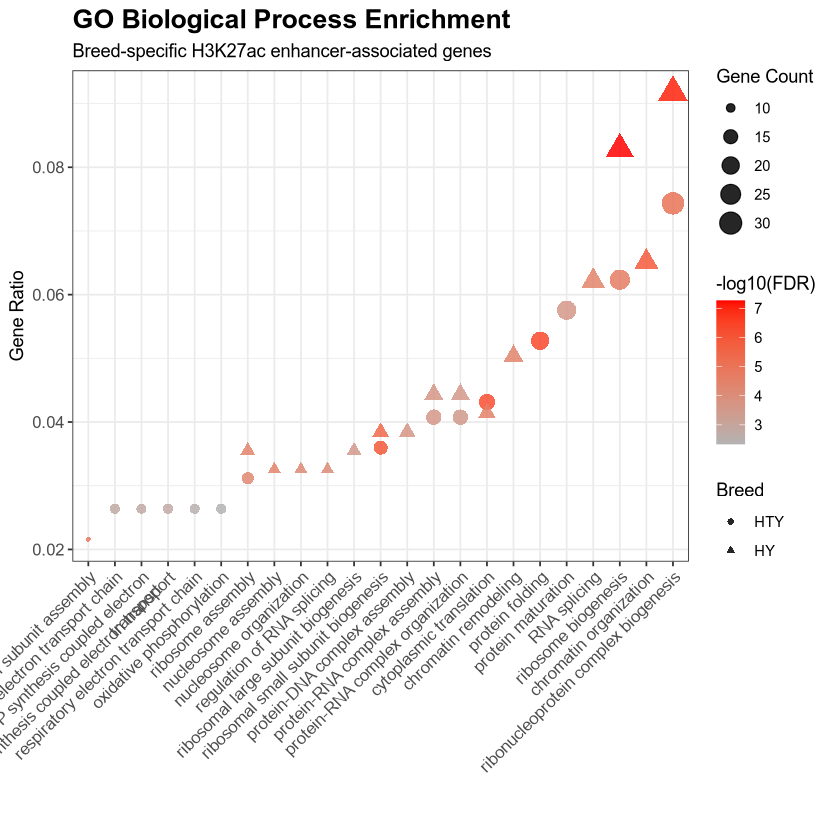

In [20]:
library(dplyr)
library(ggplot2)
library(stringr)

# ============================================================
# 1. 合并 HY 和 HTY GO 结果
# ============================================================

hy_go$Breed <- "HY"
hty_go$Breed <- "HTY"

go_all <- bind_rows(
    hy_go,
    hty_go
)


# ============================================================
# 2. 计算 GeneRatio 数值
# ============================================================

go_all <- go_all %>%
    mutate(
        GeneRatio_num = sapply(
            strsplit(GeneRatio, "/"),
            function(x) as.numeric(x[1]) / as.numeric(x[2])
        ),
        negLog10Padj = -log10(p.adjust)
    )


# ============================================================
# 3. 每个品种选择 Top 15 GO term
# ============================================================

go_top <- go_all %>%
    group_by(Breed) %>%
    arrange(p.adjust, .by_group = TRUE) %>%
    slice_head(n = 15) %>%
    ungroup()


# ============================================================
# 4. 整理 GO term 顺序
# ============================================================

go_top <- go_top %>%
    mutate(
        Description = str_wrap(
            Description,
            width = 50
        )
    )

# 按 GeneRatio 排序
go_top$Description <- factor(
    go_top$Description,
    levels = unique(
        go_top$Description[
            order(go_top$GeneRatio_num)
        ]
    )
)

p <- ggplot(
    go_top,
    aes(
        x = GeneRatio_num,
        y = Description,
        size = Count,
        color = negLog10Padj,
        shape = Breed
    )
) +
    geom_point(alpha = 0.85) +
    scale_color_gradient(
        low = "grey70",
        high = "red"
    ) +
    labs(
        x = "Gene Ratio",
        y = NULL,
        size = "Gene Count",
        color = "-log10(FDR)",
        shape = "Breed",
        title = "GO Biological Process Enrichment",
        subtitle = "Breed-specific H3K27ac enhancer-associated genes"
    ) +
    coord_flip() +
    theme_bw() +
	theme(
		plot.title = element_text(
			size = 16,
			face = "bold"
		),
		plot.subtitle = element_text(
			size = 11
		),
		axis.text.x = element_text(
			size = 10,
			angle = 45,
			hjust = 1,
			vjust = 1
		),
		axis.text.y = element_text(
			size = 10
		),
		legend.position = "right"
	)
print(p)

ggsave(
    "HY_HTY_H3K27ac_specific_GO_BP_combined_dotplot_rotated.pdf",
    p,
    width = 35,
    height = 10
)
